# Part 2 – Promotions Acquisition: which offer depth brings in the most revenue?

**Question.** Among people who aren't yet members, how much revenue does each discount depth bring in over the following seasons, which depth works best, and do offers pay at all?

**Findings** (details and checks below):

* **\$5 off is the best depth tested.** Before the cut, it brings in +\$3.11 per prospect more than \$1 off over four seasons. Revenue is still rising at \$5, so the best depth may lie beyond the tested range.
* **Offers pay.** Extending the randomized depth curve back to no offer, \$5 off gains \$3.66–\$3.98 per prospect over making no offer. Prospects who weren't offered, used only as a cross-check, give a similar \$3.63.
* **After the cut, \$5 off is still best**, and going from \$1 to \$5 off adds about the same: +\$2.34 against +\$2.49 for pre-cut spring offers, over three seasons (difference −\$0.14, 95% CI −\$0.38 to +\$0.10).

**Definitions**

* **Prospect.** A customer in one of the five promo regions who was not a member last season and has never been one (new customers only). Panem has no offers, so it is excluded.
* **Depth.** \$1–\$5 off the base price in force (\$15, or \$12 from spring 2019). The promotions engine decides who is offered using business rules, but **the depth of an offer is randomized**, so comparisons between depths are causal. Prospects who weren't offered appear only as a cross-check in section 4.
* **V4 / V3.** Revenue from a prospect in the offer season and the next 3 / 2 seasons, whenever they join within that window. Non-joiners count as \$0.

---

In [121]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

import utils as u

u.apply_style()
CUT = u.CUT_T                                                # spring 2019
OFFER_LABELS = [f'${k} off' for k in range(1, 6)]
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#52514e'

panel = u.load_panel('data/customer_panel.csv', extra_cols=('customer_id', 'discount_flag'))

## 1. Build the customer-season frame

In [122]:
df = panel.sort_values(['customer_id', 't']).reset_index(drop=True)
member = df.groupby('customer_id')['sign_up_flag']

df['prev_member'] = member.shift(1)                                            # NaN in winter 2017
df['ever_member_before'] = member.cummax().groupby(df['customer_id']).shift(1)
df['base_price'] = np.where(df['region_name'].ne(u.CONTROL) & df['t'].ge(CUT), 12, 15)
df['depth'] = np.where(df['discount_flag'].eq(1), df['base_price'] - df['membership_price'], 0)   # 0 = not offered
df['revenue'] = df['sign_up_flag'] * df['membership_price']

rev = df.groupby('customer_id')['revenue']
df['v3'] = df['revenue'] + rev.shift(-1) + rev.shift(-2)                       # offer season + next 2
df['v4'] = df['v3'] + rev.shift(-3)                                            # offer season + next 3

later = [member.shift(-k) for k in (1, 2, 3)]
df['joined_now'] = df['sign_up_flag']                                          # joined in the offer season
df['joined_in_4'] = pd.concat([df['sign_up_flag'], *later], axis=1).max(axis=1)

# Check: offers are $1-$5 off in both periods, and Panem never gets offers
period = np.where(df['t'].ge(CUT), 'post-cut', 'pre-cut')
print('Offers in Panem:', int(df.loc[df['region_name'].eq(u.CONTROL), 'discount_flag'].sum()))
df.assign(period=period).groupby(['discount_flag', 'period', 'depth']).size().unstack('depth', fill_value=0)

Offers in Panem: 0


depth                         0       1       2       3       4       5
discount_flag period                                                   
0             post-cut  1059593       0       0       0       0       0
              pre-cut   3546890       0       0       0       0       0
1             post-cut        0   93792   94151   94245   94109   94377
              pre-cut         0  208568  208670  208951  208634  209088

## 2. Prospects and analysis samples

Each filter is applied in turn. Winter 2017 is dropped because the season before it isn't observed.

In [123]:
filters = {
    'promo-region customer-seasons': df['region_name'].ne(u.CONTROL),
    '... season before is observed': df['t'].ge(1),
    '... not a member last season': df['prev_member'].eq(0),
    '... never a member before (new customers)': df['ever_member_before'].eq(0),
}
keep = pd.Series(True, index=df.index)
funnel = {}
for label, condition in filters.items():
    keep &= condition
    funnel[label] = int(keep.sum())
prospects = df[keep]
display(pd.Series(funnel, name='rows').to_frame())

samples = {
    'Pre-cut, 4 seasons': prospects[prospects['t'] + 3 < CUT],     # offers spring 2017 - spring 2018
    'Pre-cut, 3 seasons': prospects[prospects['t'] + 2 < CUT],     # offers spring 2017 - summer 2018
    'Post-cut, 3 seasons': prospects[prospects['t'].eq(CUT)],      # offers spring 2019
}

# Check: depth is randomized, so offers should split evenly across $1-$5 (20% each)
shares = pd.DataFrame({name: d.loc[d['depth'].ge(1), 'depth'].value_counts(normalize=True).sort_index()
                       for name, d in samples.items()}).T
shares.columns = OFFER_LABELS
shares.insert(0, 'share offered', [d['discount_flag'].mean() for d in samples.values()])
shares.round(3)

,rows
promo-region customer-seasons,4292232
... season before is observed,3934546
... not a member last season,3346845
... never a member before (new customers),3074020


,share offered,$1 off,$2 off,$3 off,$4 off,$5 off
"Pre-cut, 4 seasons",0.250,0.199,0.201,0.200,0.200,0.200
"Pre-cut, 3 seasons",0.250,0.200,0.200,0.200,0.200,0.200
"Post-cut, 3 seasons",0.249,0.201,0.202,0.199,0.199,0.199


## 3. Main result: which depth works best (pre-cut, four seasons)

In [124]:
pre4 = samples['Pre-cut, 4 seasons']
offered4 = pre4[pre4['depth'].ge(1)]

# Where V4 comes from: share joining within the window x revenue per joiner
decomp = offered4.groupby('depth').agg(offers=('v4', 'size'),
                                       joined_in_offer_season=('joined_now', 'mean'),
                                       joined_within_4_seasons=('joined_in_4', 'mean'),
                                       V4=('v4', 'mean'))
decomp['revenue_per_joiner'] = decomp['V4'] / decomp['joined_within_4_seasons']
decomp.index = OFFER_LABELS
display(decomp.round(3))

# Effect of each depth vs $1 off, with region and offer-season fixed effects; SEs clustered by customer
v4_fit = u.fit_ltv(offered4, 'v4')
    
terms = [f'C(depth)[T.{k}]' for k in range(2, 6)]
ci = v4_fit.conf_int().loc[terms]
effects = pd.DataFrame({'gain vs $1 off ($)': v4_fit.params[terms].to_numpy(),
                        'ci_low': ci[0].to_numpy(), 'ci_high': ci[1].to_numpy()}, index=OFFER_LABELS[1:])
display(effects.round(3))

,offers,joined_in_offer_season,joined_within_4_seasons,V4,revenue_per_joiner
$1 off,79128,0.037,0.159,4.013,25.264
$2 off,79586,0.058,0.173,4.680,26.976
$3 off,79376,0.084,0.190,5.327,27.989
$4 off,79219,0.119,0.217,6.300,28.978
$5 off,79477,0.158,0.245,7.122,29.027


,gain vs $1 off ($),ci_low,ci_high
$2 off,0.665,0.556,0.773
$3 off,1.316,1.203,1.429
$4 off,2.282,2.163,2.402
$5 off,3.105,2.982,3.228


**Reading**

* **Deeper is better throughout.** Compared with \$1 off, revenue per prospect rises by +\$0.67, +\$1.32, +\$2.28 and +\$3.11 at \$2–\$5 off. With and without fixed effects the estimates agree within \$0.01, as randomized depths should.
* **Conversion drives it.** The share joining within four seasons rises from 15.9% at \$1 off to 24.5% at \$5 off. Revenue per joiner also rises (\$25 → \$29): deeper offers make people join sooner, so they pay for more seasons within the window, which outweighs the lower first-season price.
* **\$5 off is best within \$1–\$5** and beats \$4 off by +\$0.82 (95% CI \$0.69–\$0.96). Each extra dollar still adds \$0.65–\$0.97, so the data can't say where revenue would peak.

## 4. Do offers pay at all?

There is no randomized no-offer group: who is offered is a business rule. So the main estimate extends the randomized depth curve one step back, to no offer. Prospects who weren't offered that season serve as a cross-check.

In [125]:
mean = u.depth_means(v4_fit)['estimate']
x = mean.index.to_numpy(dtype=float)
no_offer = {
    'Straight line through $1-$5 off': np.polyval(np.polyfit(x, mean.to_numpy(), 1), 0),
    'Curve through $1-$5 off': np.polyval(np.polyfit(x, mean.to_numpy(), 2), 0),
    'Cross-check: prospects not offered': pre4.loc[pre4['depth'].eq(0), 'v4'].mean(),
}
payoff = pd.DataFrame({'V4 with no offer': no_offer})
payoff['gain at $1 off'] = mean[1] - payoff['V4 with no offer']
payoff['gain at $5 off'] = mean[5] - payoff['V4 with no offer']
payoff['rests on'] = ['randomized depths; the trend continues one more step',
                      'randomized depths; the curve continues one more step',
                      'the business rule being unrelated to joining']
payoff.round(2)

,V4 with no offer,gain at $1 off,gain at $5 off,rests on
Straight line through $1-$5 off,3.14,0.87,3.98,randomized depths; the trend continues one mor...
Curve through $1-$5 off,3.46,0.56,3.66,randomized depths; the curve continues one mor...
Cross-check: prospects not offered,3.49,0.52,3.63,the business rule being unrelated to joining


,estimate,se,ci_low,ci_high
depth,,,,
1,4.01,0.04,3.94,4.09
2,4.68,0.04,4.60,4.76
3,5.33,0.05,5.24,5.42
4,6.30,0.05,6.20,6.39
5,7.12,0.05,7.02,7.22


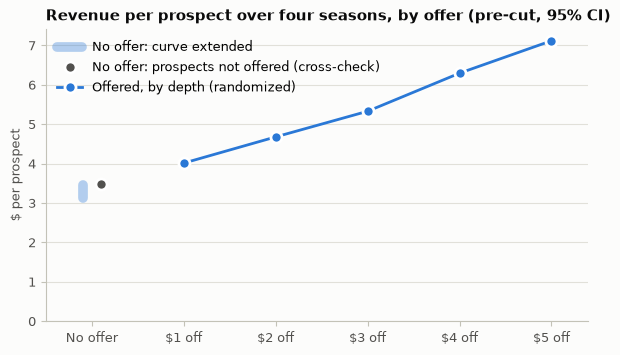

In [126]:
m = u.depth_means(v4_fit) 
extended = [no_offer['Straight line through $1-$5 off'], no_offer['Curve through $1-$5 off']]
display(m.round(2))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar(m.index, m['estimate'], yerr=[m['estimate'] - m['ci_low'], m['ci_high'] - m['estimate']],
            fmt='o-', color=BLUE, lw=2, ms=8, mec='white', mew=2, elinewidth=2, capsize=0,
            label='Offered, by depth (randomized)')
ax.plot([-0.1, -0.1], [min(extended), max(extended)], color=BLUE, alpha=0.35, lw=7, solid_capstyle='round',
        label='No offer: curve extended')
ax.plot([0.1], [no_offer['Cross-check: prospects not offered']], 'o', color=GRAY, ms=8, mec='white', mew=2,
        label='No offer: prospects not offered (cross-check)')
ax.set_xticks(range(6), ['No offer'] + OFFER_LABELS)
ax.set_xlim(-0.5, 5.4)
ax.set_ylim(0, None)
ax.set_ylabel('$ per prospect')
ax.set_title('Revenue per prospect over four seasons, by offer (pre-cut, 95% CI)', loc='left')
ax.legend(frameon=False, loc='upper left')
plt.show()

**Reading**

* **Offers pay.** Extending the curve to no offer gives \$3.14 (straight line) or \$3.46 (curve), so \$5 off gains \$3.66–\$3.98 per prospect over making no offer, and even \$1 off gains \$0.56–\$0.87.
* **The cross-check lands in the same place.** Prospects who weren't offered brought in \$3.49, close to where the curve points. Because who gets offered is a business rule, this supports the result rather than carrying it.

## 5. Before vs after the cut

There is no four-season window after the cut, so this compares three-season revenue (V3) among offered prospects: spring 2019 offers against pre-cut spring offers (2017 and 2018). Only spring is observed after the cut, so the pre-cut side is restricted to spring as well.

In [132]:
pre3, post3 = samples['Pre-cut, 3 seasons'], samples['Post-cut, 3 seasons']
pre3 = pre3[pre3['t'] % 4 == 1]                        # spring 2017 and 2018 only, to match spring 2019
offered3 = {'pre-cut': pre3[pre3['depth'].ge(1)], 'post-cut': post3[post3['depth'].ge(1)]}

compare = pd.DataFrame({f'{p} V3': d.groupby('depth')['v3'].mean() for p, d in offered3.items()})
for p in offered3:
    compare[f'{p} gain vs $1 off'] = compare[f'{p} V3'] - compare.loc[1, f'{p} V3']
compare.index = OFFER_LABELS
display(compare.round(2))

,pre-cut V3,post-cut V3,pre-cut gain vs $1 off,post-cut gain vs $1 off
$1 off,2.99,2.37,0.00,0.00
$2 off,3.49,2.84,0.50,0.47
$3 off,4.01,3.36,1.02,0.99
$4 off,4.68,4.01,1.69,1.64
$5 off,5.48,4.71,2.49,2.34


In [133]:
# Do deeper offers pay differently after the cut? Like with like: spring 2019 vs pre-cut spring offers
pooled = pd.concat([offered3['pre-cut'].assign(post=0), offered3['post-cut'].assign(post=1)])
inter = []
for k in range(2, 6):
    pooled[f'd{k}_x_post'] = (pooled['depth'].eq(k) & pooled['post'].eq(1)).astype(int)
    inter.append(f'd{k}_x_post')
fit_pooled = smf.ols('v3 ~ C(depth) + ' + ' + '.join(inter) + ' + C(region_name) + C(t)', data=pooled).fit(
    cov_type='cluster', cov_kwds={'groups': pooled['customer_id']})

# Each interaction: how much the gain over $1 off at that depth changed after the cut
ci = fit_pooled.conf_int().loc[inter]
display(pd.DataFrame({'change in gain vs $1 off': fit_pooled.params[inter].to_numpy(),
                      'ci_low': ci[0].to_numpy(), 'ci_high': ci[1].to_numpy()}, index=OFFER_LABELS[1:]).round(3))
wald = fit_pooled.wald_test(', '.join(f'{x} = 0' for x in inter), scalar=True)
print(f"All four changes = 0: chi2 = {float(wald.statistic):.1f}, p = {float(wald.pvalue):.2f}")


,change in gain vs $1 off,ci_low,ci_high
$2 off,-0.030,-0.241,0.182
$3 off,-0.029,-0.252,0.194
$4 off,-0.040,-0.272,0.192
$5 off,-0.139,-0.379,0.101


All four changes = 0: chi2 = 1.3, p = 0.85


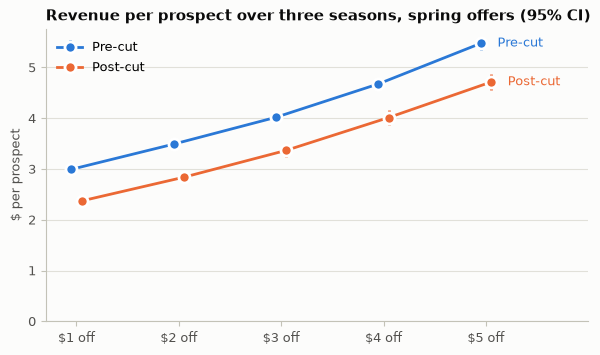

In [134]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for (name, data), color, shift in [(('Pre-cut', offered3['pre-cut']), BLUE, -0.05),
                                   (('Post-cut', offered3['post-cut']), ORANGE, 0.05)]:
    m = u.depth_means(u.fit_ltv(data, 'v3'))          # level at each depth, from the fixed-effects model
    ax.errorbar(m.index + shift, m['estimate'], yerr=[m['estimate'] - m['ci_low'], m['ci_high'] - m['estimate']],
                fmt='o-', color=color, lw=2, ms=8, mec='white', mew=2, elinewidth=2, capsize=0, label=name)
    ax.annotate(name, (m.index[-1] + shift, m['estimate'].iloc[-1]), xytext=(12, 0),
                textcoords='offset points', va='center', color=color)
ax.set_xticks(range(1, 6), OFFER_LABELS)
ax.set_xlim(0.7, 6.0)
ax.set_ylim(0, None)
ax.set_ylabel('$ per prospect')
ax.set_title('Revenue per prospect over three seasons, spring offers (95% CI)', loc='left')
ax.legend(frameon=False, loc='upper left')
plt.show()


**Reading**

* **\$5 off is best in both periods.**
* **Going deeper pays about the same after the cut.** Moving from \$1 to \$5 off adds +\$2.34 per prospect after the cut and +\$2.49 before. The change, −\$0.14 (95% CI −\$0.38 to +\$0.10), is not significant, and neither is the change at any other depth (joint p = 0.85).
* **Why spring only.** The season fixed effects shift each season's level, not how steeply revenue rises with depth. Only spring is observed after the cut, so comparing it with a mix of pre-cut seasons would confuse the effect of the cut with differences between seasons.
* **Revenue is lower at every depth after the cut** (\$4.71 vs \$5.48 at \$5 off). Each member pays less at the \$12 base, but levels also differ from year to year, so the comparison above uses gains, not levels.

## 6. Robustness

In [ ]:
first = offered4.sort_values('t').drop_duplicates('customer_id')    # each customer's first offer
rob = pd.DataFrame({
    'Main: all revenue in the window': offered4.groupby('depth')['v4'].mean(),
    'Only joins in the offer season': (offered4['joined_now'] * offered4['v4']).groupby(offered4['depth']).mean(),
    'First offer per customer': first.groupby('depth')['v4'].mean(),
}).T
rob.columns = OFFER_LABELS
rob['best'] = rob[OFFER_LABELS].idxmax(axis=1)
rob['$5 off − $1 off'] = rob['$5 off'] - rob['$1 off']
rob.round(2)

,$1 off,$2 off,$3 off,$4 off,$5 off,best,$5 off − $1 off
Main: all revenue in the window,4.01,4.68,5.33,6.30,7.12,$5 off,3.11
Only joins in the offer season,1.32,2.11,2.97,4.11,5.18,$5 off,3.86
First offer per customer,4.16,4.95,5.63,6.65,7.67,$5 off,3.50


**Reading**

* **\$5 off is best in every version.**
* **Counting only joins in the offer season overstates the gain** (+\$3.86 from \$1 to \$5 off, against +\$3.11). It credits the offer with joins that would have happened a season or two later anyway.
* **First offer per customer** gives a somewhat larger gain (+\$3.50). Fresh prospects respond more than those who have already passed on earlier offers.

**Caveats**

* **Revenue, not margin.** If each member brings costs, deeper offers look less attractive.
* **Tested range.** Only \$1–\$5 off was tested, and revenue is still rising at \$5.
* **Dollars vs percent.** \$5 off is 33% of \$15 but 42% of \$12.
* **New customers only.** Returning ex-members (about 8% of non-members) are excluded.